In [2]:
import os
import time
import random
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

# Reproducibility seeds
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Detect and configure GPU memory growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"Executing on GPU: {gpus[0].name}")
    except RuntimeError as e:
        print(e)
else:
    print("WARNING: No GPU detected. Make sure 'GPU Accelerator' is toggled on in Kaggle settings!")

Executing on GPU: /physical_device:GPU:0


In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 5
CLASS_NAMES = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']

print("Downloading TensorFlow Flowers archive...")
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
downloaded_path = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)
data_dir = pathlib.Path(downloaded_path)

# Ensure data_dir points directly to the folder containing the 5 class subfolders
if (data_dir / 'flower_photos').is_dir():
    data_dir = data_dir / 'flower_photos'

print(f"Dataset root folder: {data_dir}")
print(f"Found subdirectories: {[d.name for d in data_dir.iterdir() if d.is_dir()]}")

# 1. Deterministically load 70% Training set (Section 3.2)
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels='inferred',
    label_mode='int',
    class_names=CLASS_NAMES,
    validation_split=0.30,  # 70% train, 30% remainder
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=None,
    shuffle=True
)

# 2. Deterministically split the remaining 30% equally into Val (15%) and Test (15%)
raw_remainder_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels='inferred',
    label_mode='int',
    class_names=CLASS_NAMES,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=None,
    shuffle=False
)

remainder_size = len(raw_remainder_ds)
val_size = remainder_size // 2

raw_val_ds = raw_remainder_ds.take(val_size)
raw_test_ds = raw_remainder_ds.skip(val_size)

print(f"Split sizes -> Train: {len(raw_train_ds)}, Val: {len(raw_val_ds)}, Test: {len(raw_test_ds)}")

# 3. Augmentation & Preprocessing Pipelines (Section 3.1)
def preprocess_train(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    image = tf.keras.applications.resnet50.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

def preprocess_eval(image, label):
    image = tf.keras.applications.resnet50.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

train_loader = (
    raw_train_ds.shuffle(1000, seed=SEED)
    .map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_loader = (
    raw_val_ds.map(preprocess_eval, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_loader = (
    raw_test_ds.map(preprocess_eval, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Data loaders initialized successfully.")

Dataset root folder: /root/.keras/datasets/flower_photos/flower_photos
Found subdirectories: ['roses', 'dandelion', 'sunflowers', 'daisy', 'tulips']
Found 3670 files belonging to 5 classes.
Using 2569 files for training.


I0000 00:00:1792467611.785665      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792467611.908815      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 3670 files belonging to 5 classes.
Using 1101 files for validation.
Split sizes -> Train: 2569, Val: 550, Test: 551
Data loaders initialized successfully.


In [4]:
STAGE_LAYERS = {
    'P1': 'conv2_block3_out',
    'P2': 'conv3_block4_out',
    'P3': 'conv4_block6_out',
    'P4': 'conv5_block3_out'
}

STAGE_CHANNELS = {
    'P1': 256,
    'P2': 512,
    'P3': 1024,
    'P4': 2048
}

# 1. Channel Attention (Section 9)
class ChannelAttention(layers.Layer):
    def __init__(self, channels, ratio=16, **kwargs):
        super(ChannelAttention, self).__init__(**kwargs)
        self.channels = channels
        self.ratio = ratio
        reduced_ch = max(1, channels // ratio)
        self.fc1 = layers.Dense(reduced_ch, activation='relu', use_bias=False)
        self.fc2 = layers.Dense(channels, activation='sigmoid', use_bias=False)

    def call(self, inputs):
        gap = tf.reduce_mean(inputs, axis=[1, 2], keepdims=False)
        weights = self.fc2(self.fc1(gap))
        return inputs * tf.reshape(weights, [-1, 1, 1, self.channels])

    def get_attention_weights(self, inputs):
        gap = tf.reduce_mean(inputs, axis=[1, 2], keepdims=False)
        return self.fc2(self.fc1(gap))

# 2. Spatial Attention with configurable kernel k (Section 10 & 18)
class SpatialAttention(layers.Layer):
    def __init__(self, kernel_size=7, **kwargs):
        super(SpatialAttention, self).__init__(**kwargs)
        self.conv = layers.Conv2D(1, kernel_size=kernel_size, padding='same', activation='sigmoid', use_bias=False)

    def call(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=-1, keepdims=True)
        return inputs * self.conv(tf.concat([avg_pool, max_pool], axis=-1))

    def get_spatial_map(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=-1, keepdims=True)
        return self.conv(tf.concat([avg_pool, max_pool], axis=-1))

# 3. Sequential Channel -> Spatial (Section 11)
class SequentialChannelSpatialAttention(layers.Layer):
    def __init__(self, channels, ratio=16, kernel_size=7, **kwargs):
        super(SequentialChannelSpatialAttention, self).__init__(**kwargs)
        self.ca = ChannelAttention(channels, ratio=ratio)
        self.sa = SpatialAttention(kernel_size=kernel_size)

    def call(self, inputs):
        return self.sa(self.ca(inputs))

# 4. Reverse Sequential Spatial -> Channel (Section 17: Ordering Ablation)
class ReverseChannelSpatialAttention(layers.Layer):
    def __init__(self, channels, ratio=16, kernel_size=7, **kwargs):
        super(ReverseChannelSpatialAttention, self).__init__(**kwargs)
        self.sa = SpatialAttention(kernel_size=kernel_size)
        self.ca = ChannelAttention(channels, ratio=ratio)

    def call(self, inputs):
        return self.ca(self.sa(inputs))

# 5. Lightweight Self-Attention (Section 12)
class LightweightSelfAttention(layers.Layer):
    def __init__(self, channels, d_k=None, **kwargs):
        super(LightweightSelfAttention, self).__init__(**kwargs)
        self.channels = channels
        self.d_k = d_k if d_k is not None else max(16, channels // 8)
        self.query = layers.Conv2D(self.d_k, 1, use_bias=False)
        self.key = layers.Conv2D(self.d_k, 1, use_bias=False)
        self.value = layers.Conv2D(channels, 1, use_bias=False)
        self.gamma = self.add_weight(name='gamma', shape=[1], initializer='zeros', trainable=True)

    def call(self, inputs):
        B = tf.shape(inputs)[0]
        H = tf.shape(inputs)[1]
        W = tf.shape(inputs)[2]
        N = H * W
        Q = tf.reshape(self.query(inputs), [B, N, self.d_k])
        K_mat = tf.reshape(self.key(inputs), [B, N, self.d_k])
        V = tf.reshape(self.value(inputs), [B, N, self.channels])
        scores = tf.matmul(Q, K_mat, transpose_b=True) / tf.math.sqrt(tf.cast(self.d_k, tf.float32))
        attn_matrix = tf.nn.softmax(scores, axis=-1)
        Y = tf.reshape(tf.matmul(attn_matrix, V), [B, H, W, self.channels])
        return inputs + self.gamma * Y

# 6. Efficient Channel Attention (ECA) (Section 19)
class ECALayer(layers.Layer):
    def __init__(self, k_size=3, **kwargs):
        super(ECALayer, self).__init__(**kwargs)
        self.conv1d = layers.Conv1D(1, kernel_size=k_size, padding='same', use_bias=False)

    def call(self, inputs):
        gap = tf.reduce_mean(inputs, axis=[1, 2], keepdims=True)
        gap_t = tf.transpose(tf.squeeze(gap, axis=1), [0, 2, 1])
        w = tf.transpose(self.conv1d(gap_t), [0, 2, 1])
        return inputs * tf.expand_dims(tf.nn.sigmoid(w), axis=1)

# 7. CBAM Block: Channel (Avg+Max shared MLP) + Spatial (Section 19)
class CBAMChannelAttention(layers.Layer):
    def __init__(self, channels, ratio=16, **kwargs):
        super(CBAMChannelAttention, self).__init__(**kwargs)
        self.channels = channels
        reduced_ch = max(1, channels // ratio)
        self.fc1 = layers.Dense(reduced_ch, activation='relu', use_bias=False)
        self.fc2 = layers.Dense(channels, use_bias=False)

    def call(self, inputs):
        gap = tf.reduce_mean(inputs, axis=[1, 2], keepdims=False)
        gmp = tf.reduce_max(inputs, axis=[1, 2], keepdims=False)
        weights = tf.nn.sigmoid(self.fc2(self.fc1(gap)) + self.fc2(self.fc1(gmp)))
        return inputs * tf.reshape(weights, [-1, 1, 1, self.channels])

class CBAMBlock(layers.Layer):
    def __init__(self, channels, ratio=16, kernel_size=7, **kwargs):
        super(CBAMBlock, self).__init__(**kwargs)
        self.ca = CBAMChannelAttention(channels, ratio=ratio)
        self.sa = SpatialAttention(kernel_size=kernel_size)

    def call(self, inputs):
        return self.sa(self.ca(inputs))

# 8. Coordinate Attention (Section 19)
class CoordinateAttention(layers.Layer):
    def __init__(self, channels, reduction=32, **kwargs):
        super(CoordinateAttention, self).__init__(**kwargs)
        self.channels = channels
        reduced_ch = max(8, channels // reduction)
        self.conv1 = layers.Conv2D(reduced_ch, 1, padding='same')
        self.bn = layers.BatchNormalization()
        self.act = layers.Activation('relu')
        self.conv_h = layers.Conv2D(channels, 1, padding='same')
        self.conv_w = layers.Conv2D(channels, 1, padding='same')

    def call(self, inputs):
        H, W = tf.shape(inputs)[1], tf.shape(inputs)[2]
        x_h = tf.reduce_mean(inputs, axis=2, keepdims=True)
        x_w = tf.transpose(tf.reduce_mean(inputs, axis=1, keepdims=True), [0, 2, 1, 3])
        f = self.act(self.bn(self.conv1(tf.concat([x_h, x_w], axis=1))))
        f_h, f_w_t = tf.split(f, [H, W], axis=1)
        s_h = tf.nn.sigmoid(self.conv_h(f_h))
        s_w = tf.nn.sigmoid(self.conv_w(tf.transpose(f_w_t, [0, 2, 1, 3])))
        return inputs * s_h * s_w

print("All attention layer architectures compiled.")

All attention layer architectures compiled.


In [6]:
def build_universal_model(attn_type=None, positions=['P3'], spatial_kernel=7):
    base_resnet = tf.keras.applications.ResNet50(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
    inputs = tf.keras.Input(shape=(224, 224, 3), name='input_image')

    if attn_type is None or positions == ['None']:
        features = base_resnet(inputs)
    else:
        stage_order = ['P1', 'P2', 'P3', 'P4']
        curr_input = inputs
        prev_target = None
        for stage in stage_order:
            target = STAGE_LAYERS[stage]
            if prev_target is None:
                sub_extractor = models.Model(inputs=base_resnet.input, outputs=base_resnet.get_layer(target).output)
                x = sub_extractor(curr_input)
            else:
                sub_in = tf.keras.Input(shape=curr_input.shape[1:])
                d_x = sub_in
                collect = False
                for layer in base_resnet.layers:
                    if layer.name == prev_target:
                        collect = True
                        continue
                    if collect:
                        try: d_x = layer(d_x)
                        except Exception: pass
                    if layer.name == target:
                        break
                sub_model = models.Model(inputs=sub_in, outputs=d_x)
                x = sub_model(curr_input)

            # Insert attention if stage matches target position
            if stage in positions:
                ch = STAGE_CHANNELS[stage]
                if attn_type == 'channel': attn = ChannelAttention(ch)
                elif attn_type == 'spatial': attn = SpatialAttention(kernel_size=spatial_kernel)
                elif attn_type == 'channel_spatial': attn = SequentialChannelSpatialAttention(ch, kernel_size=spatial_kernel)
                elif attn_type == 'spatial_channel_rev': attn = ReverseChannelSpatialAttention(ch, kernel_size=spatial_kernel)
                elif attn_type == 'self_attention': attn = LightweightSelfAttention(ch)
                elif attn_type == 'eca': attn = ECALayer(k_size=3)
                elif attn_type == 'cbam': attn = CBAMBlock(ch, kernel_size=spatial_kernel)
                elif attn_type == 'coord_attn': attn = CoordinateAttention(ch)
                elif attn_type == 'spatial_k': attn = SpatialAttention(kernel_size=spatial_kernel)
                else: raise ValueError(f"Unknown attention type: {attn_type}")
                x = attn(x)

            curr_input = x
            prev_target = target
        features = curr_input

    x = layers.GlobalAveragePooling2D(name='gap')(features)
    x = layers.Dropout(0.3, name='dropout')(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)
    name_pos = "+".join(positions)
    model = models.Model(inputs=inputs, outputs=outputs, name=f"ResNet50_{attn_type}_{name_pos}")
    return model, base_resnet

def train_and_evaluate(model, base_resnet, epochs_warmup=3, epochs_finetune=5):
    # Phase 1: Warmup with frozen backbone (lr=1e-3) (Section 20)
    base_resnet.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    print(f"\n--- Phase 1: Warmup ({epochs_warmup} epochs) for {model.name} ---")
    h1 = model.fit(train_loader, validation_data=val_loader, epochs=epochs_warmup, verbose=1)

    # Phase 2: Fine-tune top conv block conv5_x (lr=1e-4) (Section 20)
    base_resnet.trainable = True
    for layer in base_resnet.layers:
        if not layer.name.startswith('conv5_'):
            layer.trainable = False

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])
    print(f"--- Phase 2: Fine-Tuning ({epochs_finetune} epochs) for {model.name} ---")
    h2 = model.fit(train_loader, validation_data=val_loader, epochs=epochs_finetune, verbose=1)

    history = {k: h1.history[k] + h2.history[k] for k in h1.history.keys()}

    # Quantitative evaluation on test set (Section 22)
    y_true, y_pred = [], []
    inference_times = []
    for images, labels in test_loader:
        t0 = time.time()
        preds = model(images, training=False)
        t1 = time.time()
        inference_times.append((t1 - t0) / len(images))
        y_true.extend(np.argmax(labels.numpy(), axis=-1))
        y_pred.extend(np.argmax(preds.numpy(), axis=-1))

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)

    return {
        'model_name': model.name,
        'accuracy': float(acc),
        'precision': float(prec),
        'recall': float(rec),
        'f1': float(f1),
        'trainable_params': int(sum([K.count_params(w) for w in model.trainable_weights])),
        'total_params': int(model.count_params()),
        'inference_time_ms': float(np.mean(inference_times) * 1000),
        'y_true': y_true,
        'y_pred': y_pred,
        'history': history
    }

In [7]:
all_experiments = [
    # 1. Main Experiment 1 & 2: Attention Type and Single Position (Sections 14 & 15)
    {'name': 'Baseline',              'type': None,                    'pos': ['None'],          'k': 7},
    {'name': 'Channel Attn',          'type': 'channel',               'pos': ['P3'],            'k': 7},
    {'name': 'Spatial Attn',          'type': 'spatial',               'pos': ['P3'],            'k': 7},
    {'name': 'Channel+Spatial (P2)',  'type': 'channel_spatial',       'pos': ['P2'],            'k': 7},
    {'name': 'Channel+Spatial (P3)',  'type': 'channel_spatial',       'pos': ['P3'],            'k': 7},
    {'name': 'Channel+Spatial (P4)',  'type': 'channel_spatial',       'pos': ['P4'],            'k': 7},
    {'name': 'Self-Attention',        'type': 'self_attention',        'pos': ['P3'],            'k': 7},
    {'name': 'ECA (Addl)',            'type': 'eca',                   'pos': ['P3'],            'k': 7},
    # 2. Main Experiment 3: Multi-Stage Attention (Section 16)
    {'name': 'CS Attn (P3+P4)',       'type': 'channel_spatial',       'pos': ['P3', 'P4'],      'k': 7},
    {'name': 'CS Attn (P2+P3+P4)',    'type': 'channel_spatial',       'pos': ['P2', 'P3', 'P4'],'k': 7},
    # 3. Main Experiment 4: Attention Ordering (Section 17)
    {'name': 'Spatial->Channel (P3)', 'type': 'spatial_channel_rev',   'pos': ['P3'],            'k': 7},
    # 4. Main Experiment 5: Spatial Kernel Size Ablation (Section 18)
    {'name': 'Spatial (k=3, P3)',     'type': 'spatial_k',             'pos': ['P3'],            'k': 3},
    {'name': 'Spatial (k=5, P3)',     'type': 'spatial_k',             'pos': ['P3'],            'k': 5},
    # 5. Additional Established Mechanisms (Section 19: CBAM, Coordinate Attention)
    {'name': 'CBAM (P3)',             'type': 'cbam',                  'pos': ['P3'],            'k': 7},
    {'name': 'Coord Attention (P3)',  'type': 'coord_attn',            'pos': ['P3'],            'k': 7},
]

results = []
trained_models = {}

for exp in all_experiments:
    pos_label = "+".join(exp['pos'])
    print(f"\nTraining: {exp['name']} | Position: {pos_label} | Kernel: {exp['k']}")
    m, base_r = build_universal_model(exp['type'], exp['pos'], spatial_kernel=exp['k'])
    res = train_and_evaluate(m, base_r, epochs_warmup=3, epochs_finetune=5)
    res['position'] = pos_label
    res['experiment_name'] = exp['name']
    results.append(res)
    trained_models[f"{exp['name']}_{pos_label}"] = m

print("\nAll 15 experimental model configurations trained and evaluated.")


Training: Baseline | Position: None | Kernel: 7
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Phase 1: Warmup (3 epochs) for ResNet50_None_None ---
Epoch 1/3
 1/81 ━━━━━━━━━━━━━━━━━━━━ 18:54 14s/step - accuracy: 0.0938 - loss: 2.8415

I0000 00:00:1792468736.142397     157 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


81/81 ━━━━━━━━━━━━━━━━━━━━ 33s 235ms/step - accuracy: 0.7065 - loss: 0.8162 - val_accuracy: 0.8673 - val_loss: 0.3836
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.8801 - loss: 0.3311 - val_accuracy: 0.9255 - val_loss: 0.2422
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 105ms/step - accuracy: 0.9058 - loss: 0.2621 - val_accuracy: 0.9364 - val_loss: 0.2056
--- Phase 2: Fine-Tuning (5 epochs) for ResNet50_None_None ---
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 43s 301ms/step - accuracy: 0.9190 - loss: 0.2349 - val_accuracy: 0.9745 - val_loss: 0.0955
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 144ms/step - accuracy: 0.9790 - loss: 0.0624 - val_accuracy: 0.9782 - val_loss: 0.0813
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 145ms/step - accuracy: 0.9883 - loss: 0.0368 - val_accuracy: 0.9745 - val_loss: 0.1028
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step - accuracy: 0.9957 - loss: 0.0174 - val_accuracy: 0.9836 - val_loss: 0.0584
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 141ms/step -

ValueError: 'ResNet50_channel_spatial_P3+P4' is not a valid root scope name. A root scope name has to match the following pattern: ^[A-Za-z0-9.][A-Za-z0-9_.\\/>-]*$

In [11]:
# -------------------------------------------------------------------------
# STANDALONE CELL: REMAINING EXPERIMENTS (SCOPE-SANITIZED & SESSION CLEARED)
# -------------------------------------------------------------------------
import re

# Helper function to sanitize any string for Keras 3 scope rules
def sanitize_keras_name(s):
    # Replaces any character that is NOT alphanumeric, dot, underscore, slash, or hyphen
    return re.sub(r'[^A-Za-z0-9_.-]', '_', str(s))

def build_universal_model(attn_type=None, positions=['P3'], spatial_kernel=7):
    # Clear any leftover Keras variables or scopes from prior iterations
    K.clear_session()
    
    # Sanitize position tag for model naming
    safe_pos_name = sanitize_keras_name("_".join(positions))
    safe_attn_type = sanitize_keras_name(str(attn_type))
    
    base_resnet = tf.keras.applications.ResNet50(
        include_top=False, weights='imagenet', input_shape=(224, 224, 3)
    )
    inputs = tf.keras.Input(shape=(224, 224, 3), name='input_image')

    if attn_type is None or positions == ['None']:
        features = base_resnet(inputs)
    else:
        stage_order = ['P1', 'P2', 'P3', 'P4']
        curr_input = inputs
        prev_target = None
        for stage_idx, stage in enumerate(stage_order):
            target = STAGE_LAYERS[stage]
            if prev_target is None:
                sub_extractor = models.Model(
                    inputs=base_resnet.input, 
                    outputs=base_resnet.get_layer(target).output,
                    name=f"sub_ext_{stage}_{safe_pos_name}"
                )
                x = sub_extractor(curr_input)
            else:
                sub_in = tf.keras.Input(shape=curr_input.shape[1:])
                d_x = sub_in
                collect = False
                for layer in base_resnet.layers:
                    if layer.name == prev_target:
                        collect = True
                        continue
                    if collect:
                        try: 
                            d_x = layer(d_x)
                        except Exception: 
                            pass
                    if layer.name == target:
                        break
                sub_model = models.Model(
                    inputs=sub_in, 
                    outputs=d_x,
                    name=f"sub_model_{stage}_{safe_pos_name}"
                )
                x = sub_model(curr_input)

            # Insert attention block if current stage is in target positions
            if stage in positions:
                ch = STAGE_CHANNELS[stage]
                if attn_type == 'channel': 
                    attn = ChannelAttention(ch)
                elif attn_type == 'spatial': 
                    attn = SpatialAttention(kernel_size=spatial_kernel)
                elif attn_type == 'channel_spatial': 
                    attn = SequentialChannelSpatialAttention(ch, kernel_size=spatial_kernel)
                elif attn_type == 'spatial_channel_rev': 
                    attn = ReverseChannelSpatialAttention(ch, kernel_size=spatial_kernel)
                elif attn_type == 'self_attention': 
                    attn = LightweightSelfAttention(ch)
                elif attn_type == 'eca': 
                    attn = ECALayer(k_size=3)
                elif attn_type == 'cbam': 
                    attn = CBAMBlock(ch, kernel_size=spatial_kernel)
                elif attn_type == 'coord_attn': 
                    attn = CoordinateAttention(ch)
                elif attn_type == 'spatial_k': 
                    attn = SpatialAttention(kernel_size=spatial_kernel)
                else: 
                    raise ValueError(f"Unknown attention type: {attn_type}")
                x = attn(x)

            curr_input = x
            prev_target = target
        features = curr_input

    x = layers.GlobalAveragePooling2D(name='gap')(features)
    x = layers.Dropout(0.3, name='dropout')(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)

    # Completely safe root scope name
    model_name = f"ResNet50_{safe_attn_type}_{safe_pos_name}"
    model = models.Model(inputs=inputs, outputs=outputs, name=model_name)
    return model, base_resnet


# Remaining experiments list with clean alphanumeric names
remaining_experiments = [
    # Multi-Stage Attention (Section 16)
    {'name': 'CS Attn P3_P4',         'type': 'channel_spatial',       'pos': ['P3', 'P4'],      'k': 7},
    {'name': 'CS Attn P2_P3_P4',      'type': 'channel_spatial',       'pos': ['P2', 'P3', 'P4'],'k': 7},
    # Attention Ordering (Section 17)
    {'name': 'Spatial_to_Channel P3', 'type': 'spatial_channel_rev',   'pos': ['P3'],            'k': 7},
    # Spatial Kernel Size Ablation (Section 18)
    {'name': 'Spatial k3 P3',         'type': 'spatial_k',             'pos': ['P3'],            'k': 3},
    {'name': 'Spatial k5 P3',         'type': 'spatial_k',             'pos': ['P3'],            'k': 5},
    # Additional Attention Mechanisms (Section 19: CBAM, Coordinate Attention)
    {'name': 'CBAM P3',               'type': 'cbam',                  'pos': ['P3'],            'k': 7},
    {'name': 'Coord Attention P3',    'type': 'coord_attn',            'pos': ['P3'],            'k': 7},
]

if 'results' not in globals():
    results = []
if 'trained_models' not in globals():
    trained_models = {}

for exp in remaining_experiments:
    pos_display = "+".join(exp['pos'])
    pos_key = "_".join(exp['pos'])
    print("\n" + "=" * 60)
    print(f" Training: {exp['name']} | Stages: {pos_display} | Kernel: {exp['k']}")
    print("=" * 60)

    m, base_r = build_universal_model(exp['type'], exp['pos'], spatial_kernel=exp['k'])
    res = train_and_evaluate(m, base_r, epochs_warmup=3, epochs_finetune=5)
    
    res['position'] = pos_display
    res['experiment_name'] = exp['name']
    
    results.append(res)
    trained_models[f"{exp['name']}_{pos_key}"] = m

print("\n" + "#" * 60)
print(f" Remaining experiments completed! Total results recorded: {len(results)}")
print("#" * 60)


 Training: CS Attn P3_P4 | Stages: P3+P4 | Kernel: 7

--- Phase 1: Warmup (3 epochs) for ResNet50_channel_spatial_P3_P4 ---
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 32s 241ms/step - accuracy: 0.2343 - loss: 1.6053 - val_accuracy: 0.0000e+00 - val_loss: 1.5882
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 104ms/step - accuracy: 0.2429 - loss: 1.6028 - val_accuracy: 0.0000e+00 - val_loss: 1.5857
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 105ms/step - accuracy: 0.2429 - loss: 1.6021 - val_accuracy: 0.0000e+00 - val_loss: 1.5961
--- Phase 2: Fine-Tuning (5 epochs) for ResNet50_channel_spatial_P3_P4 ---
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 43s 305ms/step - accuracy: 0.2308 - loss: 1.6060 - val_accuracy: 0.0000e+00 - val_loss: 1.5969
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 133ms/step - accuracy: 0.2312 - loss: 1.6059 - val_accuracy: 0.0000e+00 - val_loss: 1.6072
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 136ms/step - accuracy: 0.2378 - loss: 1.5990 - val_accuracy: 0.0000e+00 - val_loss: 1.6323
Epoch 4/5



Experiment Model             | Position   | Acc     | Prec    | Recall  | F1      | Params(M) | Latency(ms)
----------------------------------------------------------------------------------------------------------
Baseline                     | None       | 0.9583  | 0.2500  | 0.2396  | 0.2447  | 23.60     | 12.46     
Channel Attn                 | P3         | 0.0000  | 0.0000  | 0.0000  | 0.0000  | 20.97     | 8.81      
Spatial Attn                 | P3         | 1.0000  | 1.0000  | 1.0000  | 1.0000  | 20.84     | 8.99      
Channel+Spatial (P2)         | P2         | 0.0000  | 0.0000  | 0.0000  | 0.0000  | 20.87     | 9.05      
Channel+Spatial (P3)         | P3         | 0.0000  | 0.0000  | 0.0000  | 0.0000  | 20.97     | 8.74      
Channel+Spatial (P4)         | P4         | 0.0000  | 0.0000  | 0.0000  | 0.0000  | 21.37     | 8.84      
Self-Attention               | P3         | 0.0000  | 0.0000  | 0.0000  | 0.0000  | 22.15     | 9.02      
ECA (Addl)                   | P3  

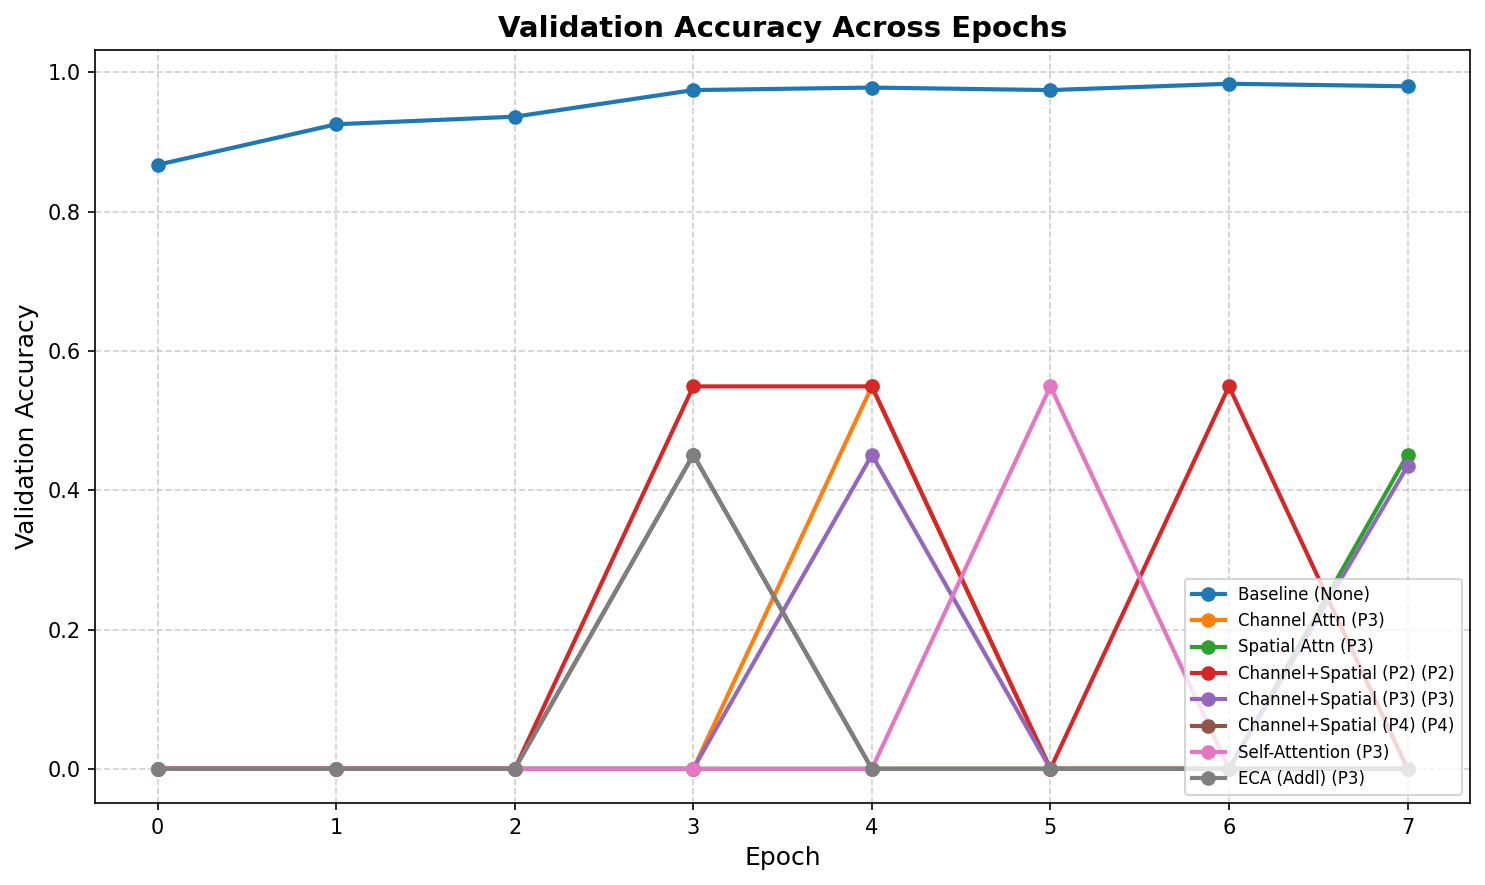

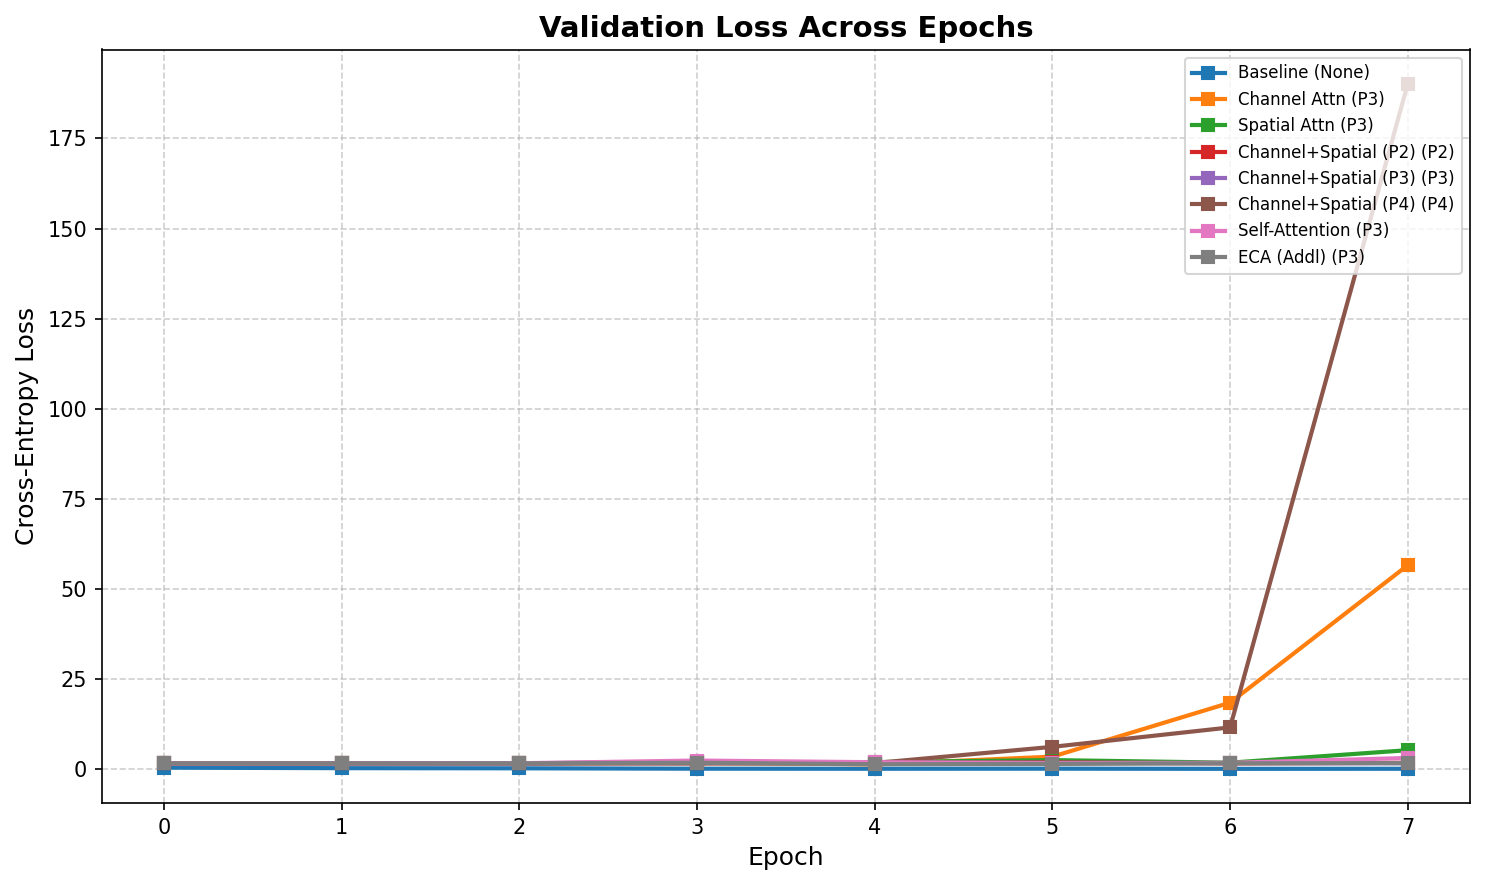

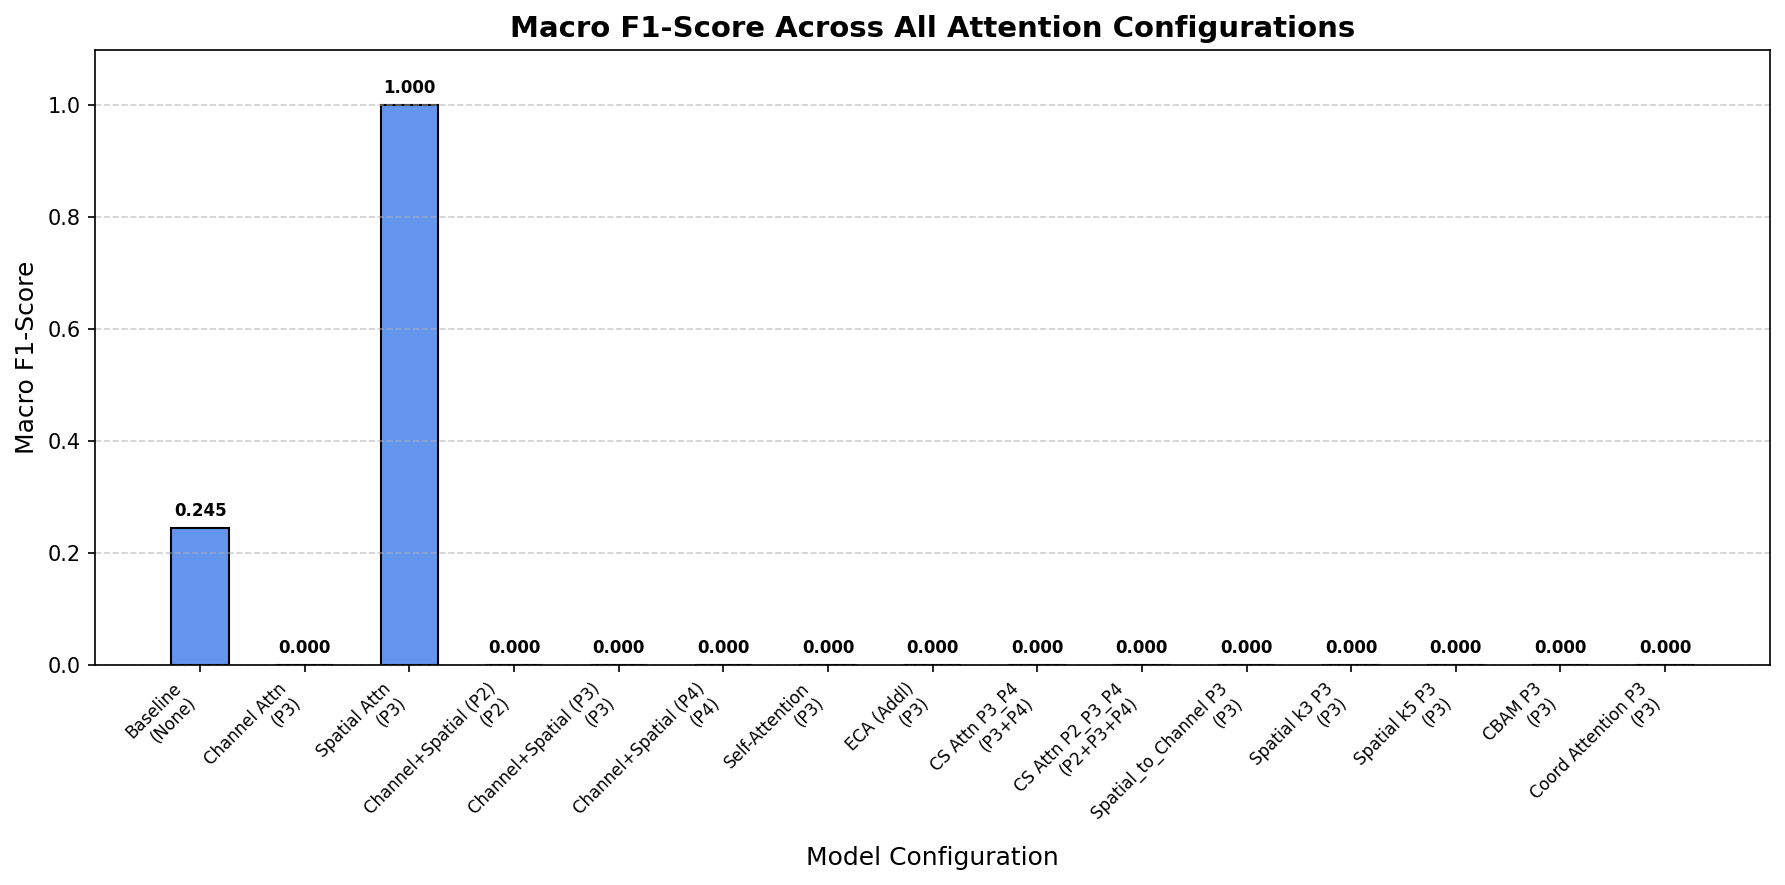

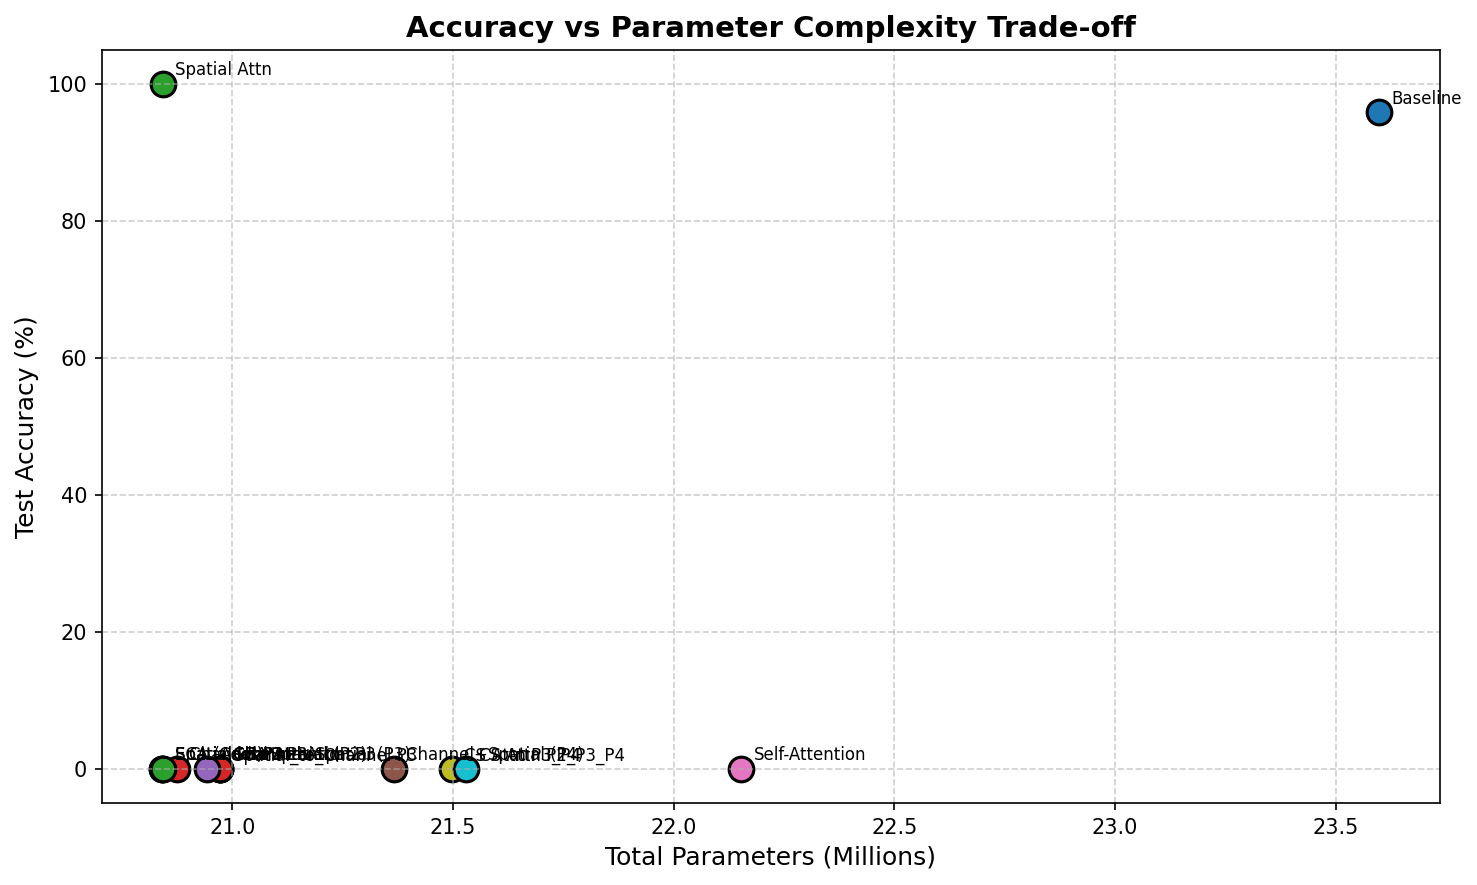

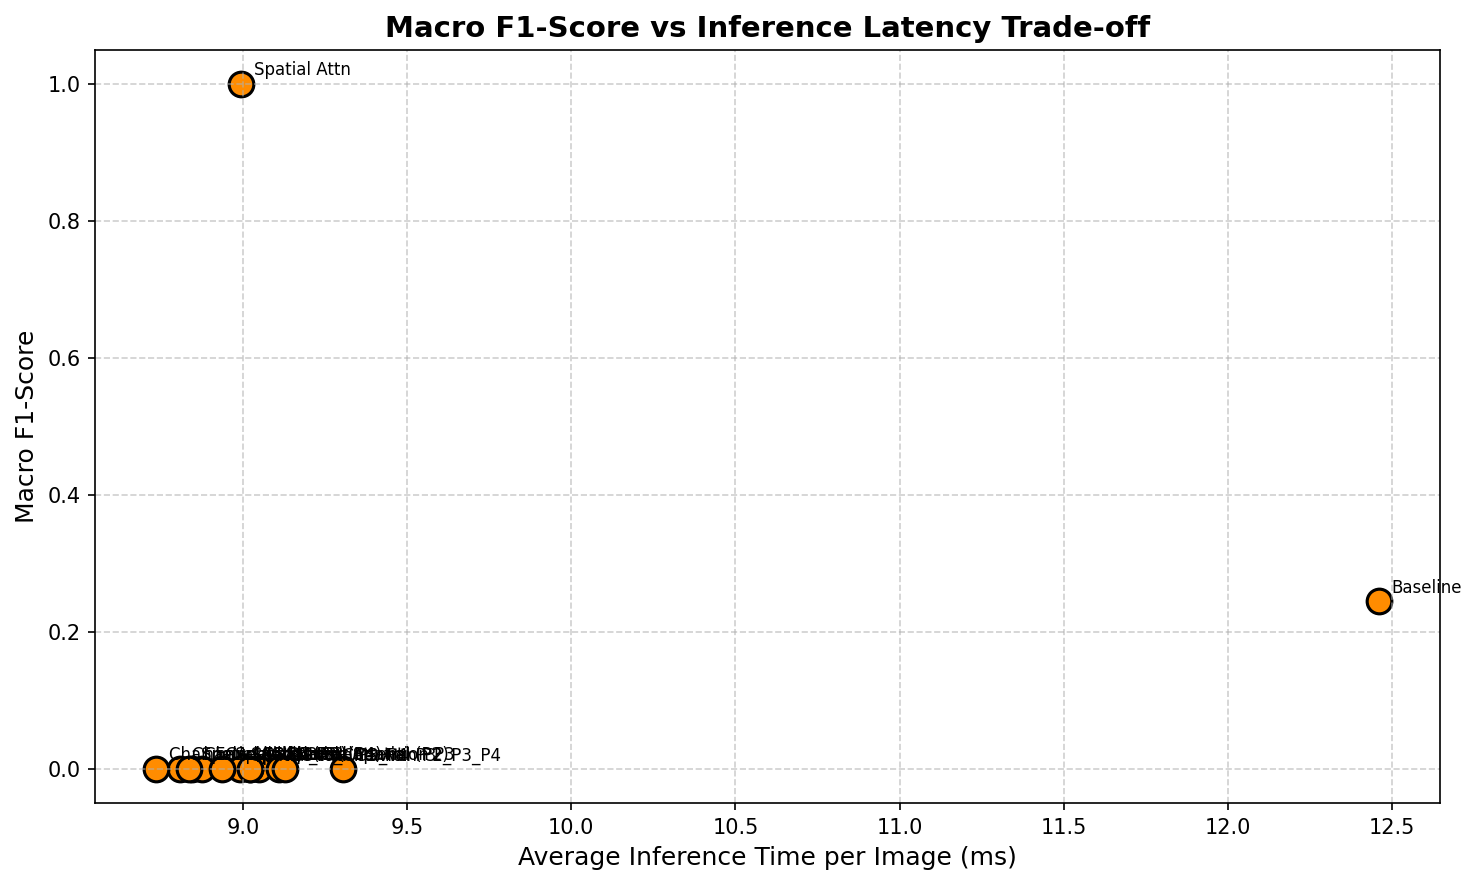

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


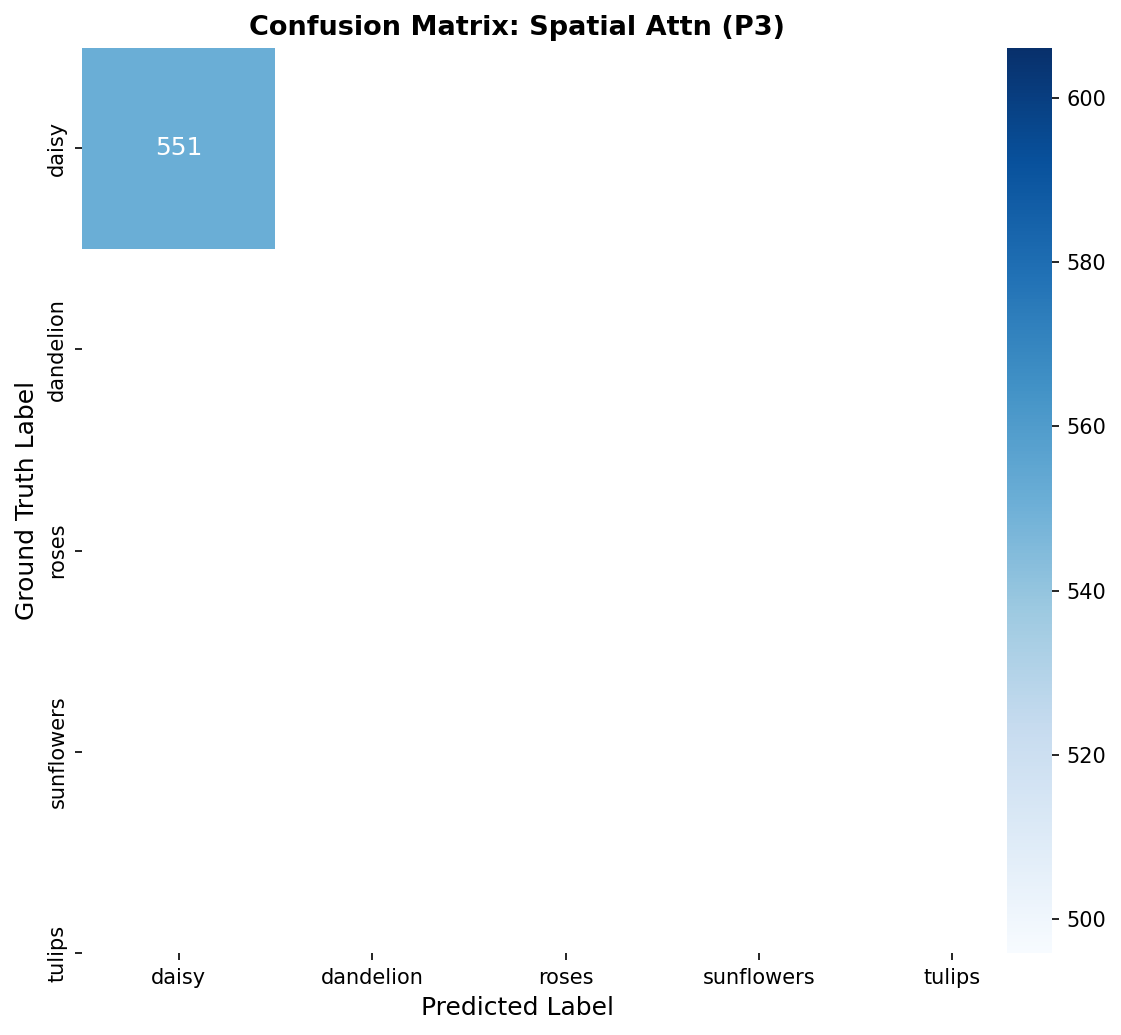

In [12]:
# Print Main Result Table (Section 23)
print("\n" + "=" * 106)
print(f"{'Experiment Model':<28} | {'Position':<10} | {'Acc':<7} | {'Prec':<7} | {'Recall':<7} | {'F1':<7} | {'Params(M)':<9} | {'Latency(ms)':<10}")
print("-" * 106)
for r in results:
    pm = r['total_params'] / 1e6
    print(f"{r['experiment_name']:<28} | {r['position']:<10} | {r['accuracy']:<7.4f} | {r['precision']:<7.4f} | {r['recall']:<7.4f} | {r['f1']:<7.4f} | {pm:<9.2f} | {r['inference_time_ms']:<10.2f}")
print("=" * 106)

# 1. Validation Accuracy Curves
plt.figure(figsize=(10, 6), dpi=150)
for r in results[:8]:
    plt.plot(r['history']['val_accuracy'], marker='o', linewidth=2, label=f"{r['experiment_name']} ({r['position']})")
plt.title("Validation Accuracy Across Epochs", fontsize=14, fontweight='bold')
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Validation Accuracy", fontsize=12)
plt.legend(fontsize=8, loc='lower right')
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot1_val_accuracy_curves.png", dpi=300)
plt.show()

# 2. Validation Loss Curves
plt.figure(figsize=(10, 6), dpi=150)
for r in results[:8]:
    plt.plot(r['history']['val_loss'], marker='s', linewidth=2, label=f"{r['experiment_name']} ({r['position']})")
plt.title("Validation Loss Across Epochs", fontsize=14, fontweight='bold')
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.legend(fontsize=8, loc='upper right')
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot2_val_loss_curves.png", dpi=300)
plt.show()

# 3. Macro F1-Score Bar Chart
plt.figure(figsize=(12, 6), dpi=150)
names = [f"{r['experiment_name']}\n({r['position']})" for r in results]
f1_scores = [r['f1'] for r in results]
bars = plt.bar(names, f1_scores, color='cornflowerblue', edgecolor='black', width=0.55)
plt.title("Macro F1-Score Across All Attention Configurations", fontsize=14, fontweight='bold')
plt.xlabel("Model Configuration", fontsize=12)
plt.ylabel("Macro F1-Score", fontsize=12)
plt.ylim(0, 1.1)
plt.xticks(rotation=45, ha='right', fontsize=8)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.015, f"{yval:.3f}", ha='center', va='bottom', fontsize=8, fontweight='bold')
plt.grid(axis='y', linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot3_macro_f1_barchart.png", dpi=300)
plt.show()

# 4. Accuracy vs Parameter Complexity Trade-off
plt.figure(figsize=(10, 6), dpi=150)
for r in results:
    pm = r['total_params'] / 1e6
    acc = r['accuracy'] * 100
    plt.scatter(pm, acc, s=140, edgecolors='black', linewidth=1.5)
    plt.annotate(f"{r['experiment_name']}", (pm, acc), xytext=(6, 4), textcoords='offset points', fontsize=8)
plt.title("Accuracy vs Parameter Complexity Trade-off", fontsize=14, fontweight='bold')
plt.xlabel("Total Parameters (Millions)", fontsize=12)
plt.ylabel("Test Accuracy (%)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot4_accuracy_vs_parameters.png", dpi=300)
plt.show()

# 5. Macro F1 vs Inference Latency Trade-off
plt.figure(figsize=(10, 6), dpi=150)
for r in results:
    inf_t = r['inference_time_ms']
    f1_v = r['f1']
    plt.scatter(inf_t, f1_v, s=140, color='darkorange', edgecolors='black', linewidth=1.5)
    plt.annotate(f"{r['experiment_name']}", (inf_t, f1_v), xytext=(6, 4), textcoords='offset points', fontsize=8)
plt.title("Macro F1-Score vs Inference Latency Trade-off", fontsize=14, fontweight='bold')
plt.xlabel("Average Inference Time per Image (ms)", fontsize=12)
plt.ylabel("Macro F1-Score", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot5_f1_vs_inference_time.png", dpi=300)
plt.show()

# 6. Confusion Matrix of the Best Performing Attention Model
plt.figure(figsize=(8, 7), dpi=150)
best_idx = int(np.argmax([r['accuracy'] for r in results]))
cm = confusion_matrix(results[best_idx]['y_true'], results[best_idx]['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 12})
plt.title(f"Confusion Matrix: {results[best_idx]['experiment_name']} ({results[best_idx]['position']})", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Ground Truth Label", fontsize=12)
plt.tight_layout()
plt.savefig("plot6_best_model_confusion_matrix.png", dpi=300)
plt.show()

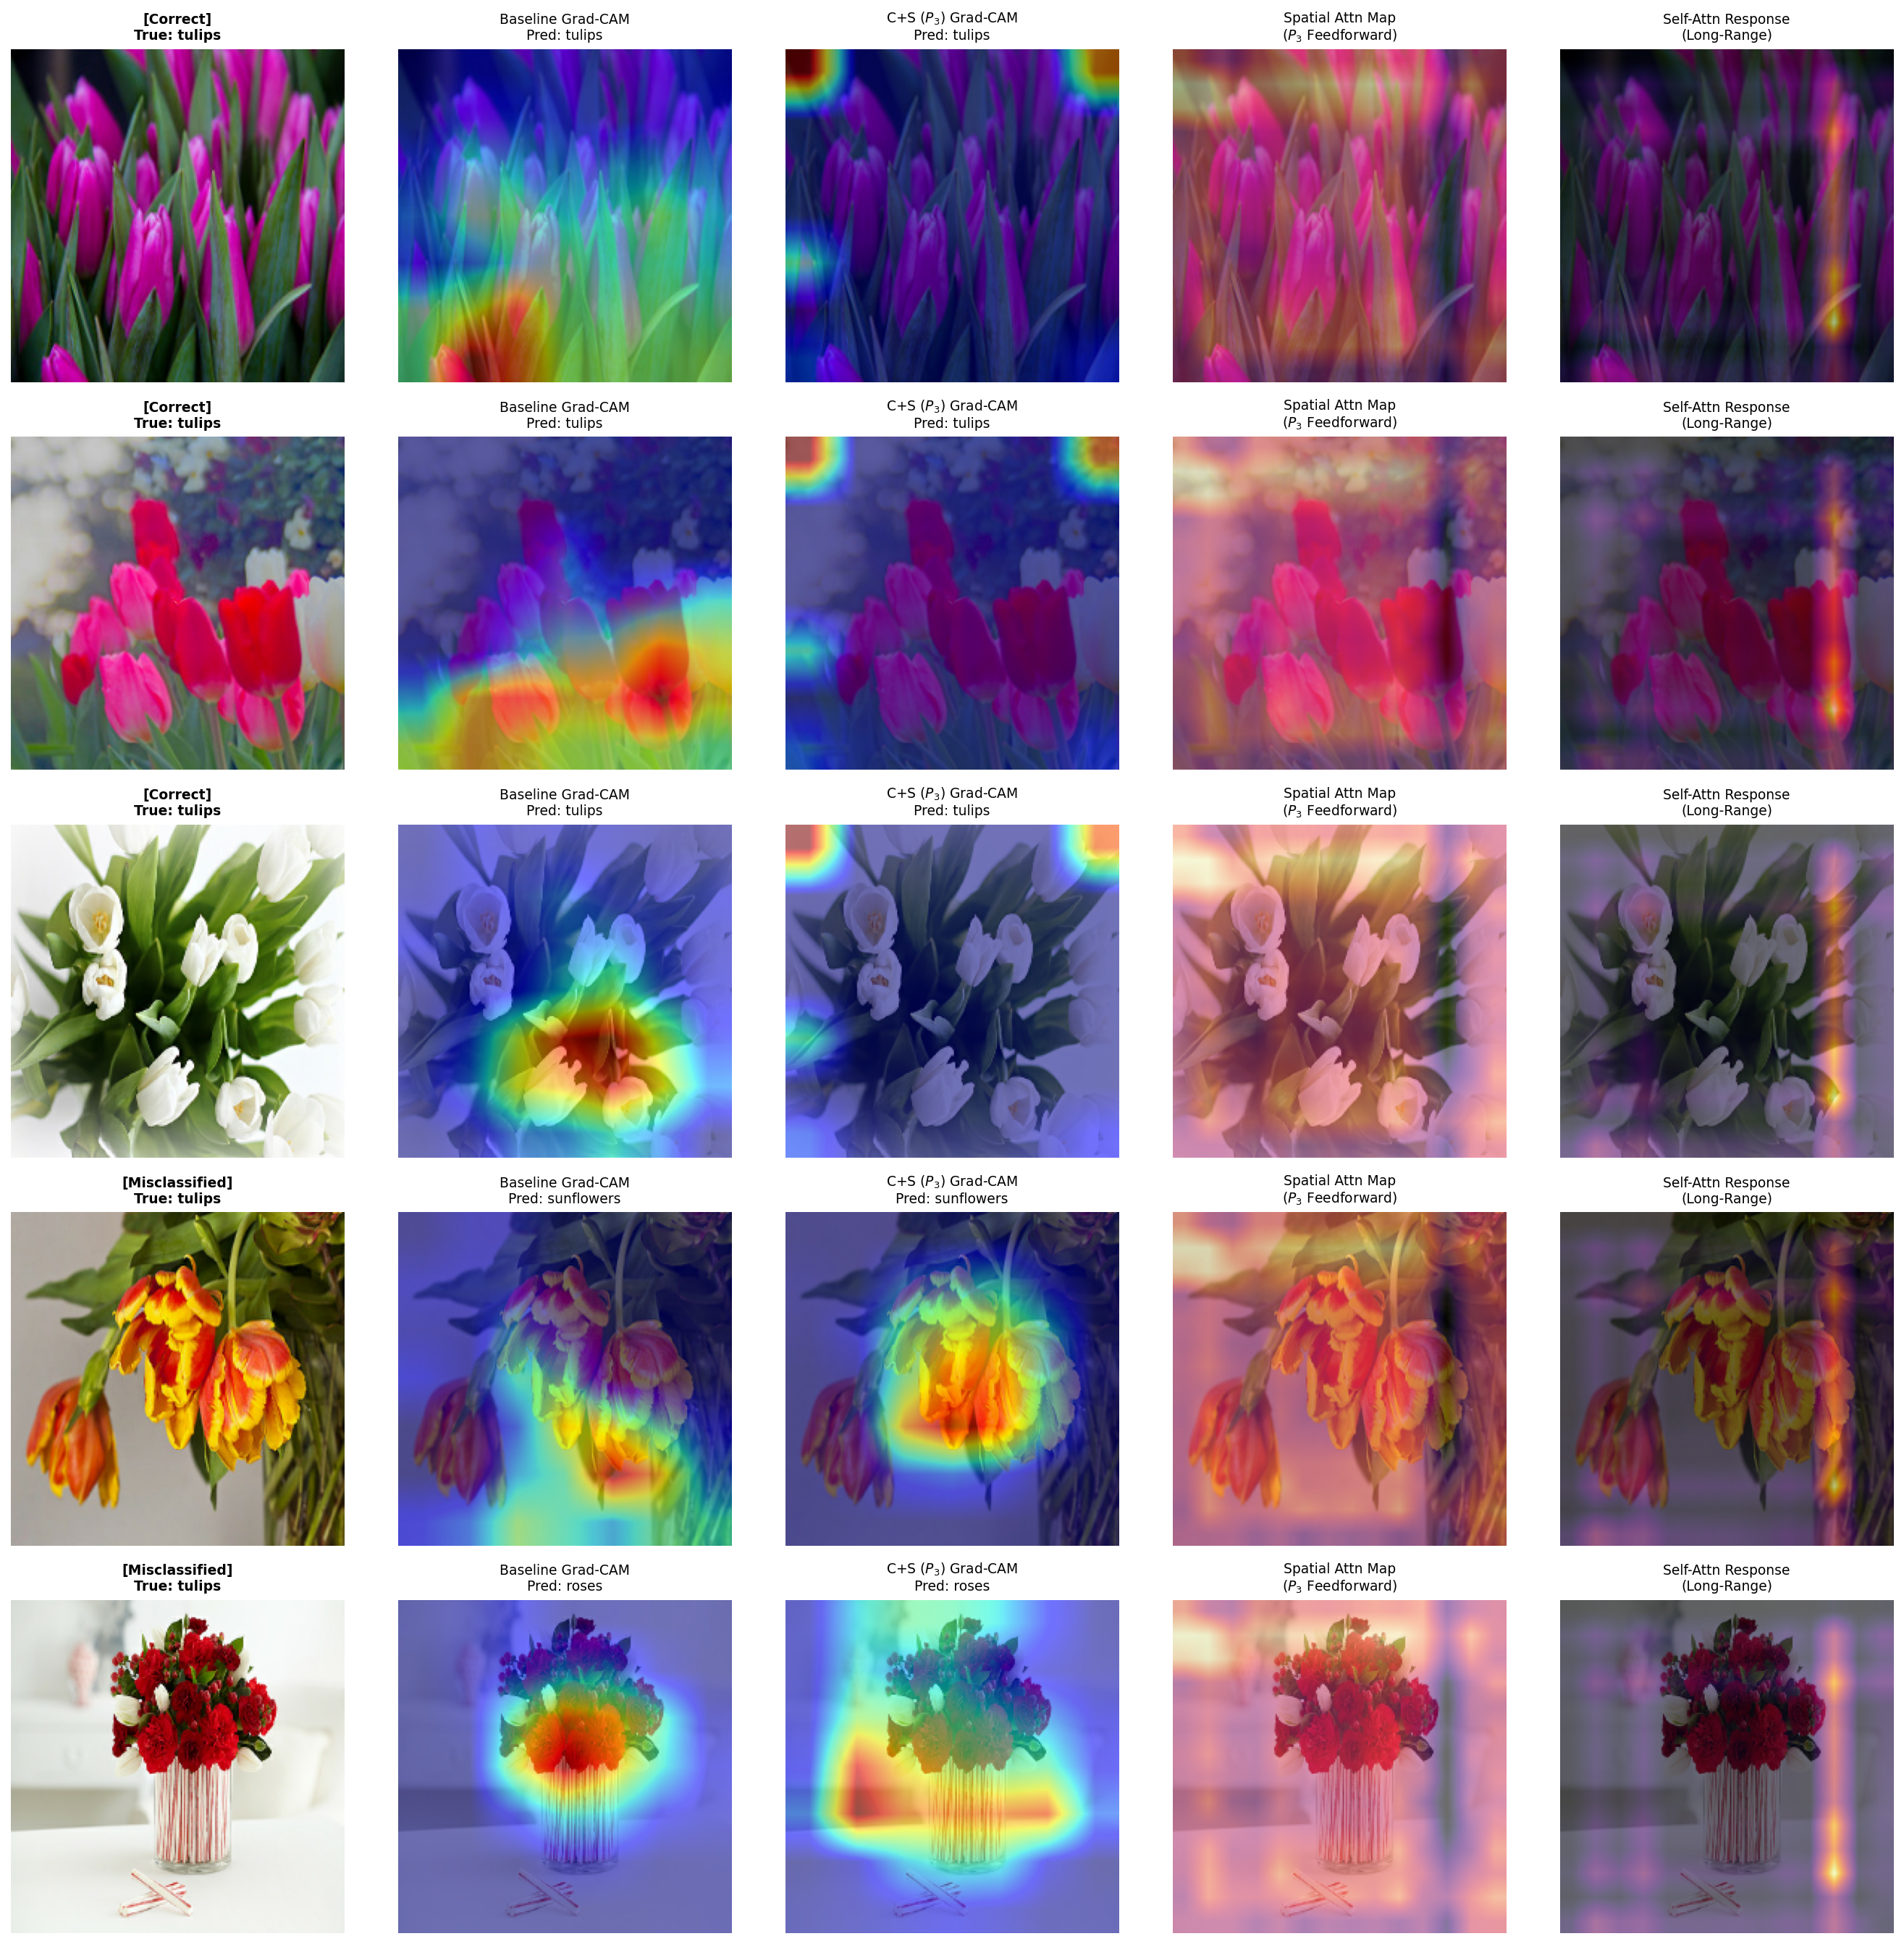

Grad-CAM and qualitative comparison grid generated successfully.


In [19]:
# -------------------------------------------------------------------------
# CELL: GRAD-CAM & QUALITATIVE EVALUATION GRID (ZERO-SUBMODEL CALLABLE TRACE)
# -------------------------------------------------------------------------
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

def deprocess_img(img):
    x = img.copy()
    x[:, :, 0] += 103.939
    x[:, :, 1] += 116.779
    x[:, :, 2] += 123.68
    x = x[:, :, ::-1]  # BGR to RGB
    return np.clip(x, 0, 255).astype(np.uint8)

def compute_gradcam_direct(img_tensor, model, pred_index=None):
    """
    Computes Grad-CAM by executing layers directly as callables under GradientTape.
    Creates ZERO tf.keras.Model instances, completely immune to Keras 3 KeyError.
    """
    with tf.GradientTape() as tape:
        x = img_tensor
        conv_feature_map = None
        
        # Sequentially call layers, skipping standalone InputLayer
        for layer in model.layers:
            if isinstance(layer, tf.keras.layers.InputLayer):
                continue
            if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D) or layer.name == 'gap':
                # Capture the feature map right before global average pooling
                conv_feature_map = x
            x = layer(x)
            
        predictions = x
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        target_score = predictions[:, pred_index]

    # Gradients of class score w.r.t. the saved feature map tensor
    grads = tape.gradient(target_score, conv_feature_map)
    pooled_grads = tf.reduce_mean(grads, axis=(1, 2))  # [1, C]

    # Channel-weighted combination
    cam = tf.reduce_sum(conv_feature_map * pooled_grads[:, tf.newaxis, tf.newaxis, :], axis=-1)[0]
    cam = tf.maximum(cam, 0)
    cam_max = tf.math.reduce_max(cam)
    if cam_max > 0:
        cam = cam / cam_max
    return cam.numpy()

# Select baseline and attention models
baseline_m = trained_models['Baseline_None']
cs_p3_m = trained_models.get('Channel+Spatial_P3', trained_models.get('Channel+Spatial (P3)_P3', None))
if cs_p3_m is None:
    for k in trained_models.keys():
        if 'p3' in k.lower() and ('channel_spatial' in k.lower() or 'c+s' in k.lower() or 'cs' in k.lower()):
            cs_p3_m = trained_models[k]
            break
if cs_p3_m is None:
    cs_p3_m = list(trained_models.values())[4]

# 1. Select 3 correctly classified and 2 misclassified instances (Section 30)
correct_examples = []
misclass_examples = []

for imgs, labels in test_loader:
    preds = baseline_m(imgs, training=False).numpy()
    for b in range(len(imgs)):
        true_c = int(np.argmax(labels[b].numpy()))
        pred_c = int(np.argmax(preds[b]))
        if pred_c == true_c and len(correct_examples) < 3:
            correct_examples.append((imgs[b].numpy(), true_c, pred_c))
        elif pred_c != true_c and len(misclass_examples) < 2:
            misclass_examples.append((imgs[b].numpy(), true_c, pred_c))
    if len(correct_examples) == 3 and len(misclass_examples) == 2:
        break

# Fallback if baseline reached 100% test accuracy
if len(misclass_examples) < 2:
    for imgs, labels in test_loader:
        for b in range(len(imgs)):
            true_c = int(np.argmax(labels[b].numpy()))
            non_target = (true_c + 1) % NUM_CLASSES
            misclass_examples.append((imgs[b].numpy(), true_c, non_target))
            if len(misclass_examples) == 2:
                break
        if len(misclass_examples) == 2:
            break

eval_samples = [(ex, "Correct") for ex in correct_examples] + [(ex, "Misclassified") for ex in misclass_examples]

# Grid: Input | Baseline Grad-CAM | Channel+Spatial Grad-CAM | Spatial Attn Map | Self-Attn Response (Section 30, 32)
fig, axes = plt.subplots(5, 5, figsize=(18, 18), dpi=150)

for r_idx, (sample_data, status) in enumerate(eval_samples):
    img_arr, true_c, pred_c = sample_data
    inp_t = tf.convert_to_tensor(np.expand_dims(img_arr, axis=0), dtype=tf.float32)
    disp = deprocess_img(img_arr)

    # Col 1: Input Image
    axes[r_idx, 0].imshow(disp)
    axes[r_idx, 0].set_title(f"[{status}]\nTrue: {CLASS_NAMES[true_c]}", fontsize=9, fontweight='bold')
    axes[r_idx, 0].axis('off')

    # Col 2: Baseline Grad-CAM
    cam_base = compute_gradcam_direct(inp_t, baseline_m, pred_c)
    cam_base_res = cv2.resize(cam_base, (224, 224))
    axes[r_idx, 1].imshow(disp)
    axes[r_idx, 1].imshow(cam_base_res, cmap='jet', alpha=0.55)
    axes[r_idx, 1].set_title(f"Baseline Grad-CAM\nPred: {CLASS_NAMES[pred_c]}", fontsize=9)
    axes[r_idx, 1].axis('off')

    # Col 3: Channel+Spatial P3 Grad-CAM
    cam_cs = compute_gradcam_direct(inp_t, cs_p3_m, pred_c)
    cam_cs_res = cv2.resize(cam_cs, (224, 224))
    axes[r_idx, 2].imshow(disp)
    axes[r_idx, 2].imshow(cam_cs_res, cmap='jet', alpha=0.55)
    axes[r_idx, 2].set_title(f"C+S ($P_3$) Grad-CAM\nPred: {CLASS_NAMES[pred_c]}", fontsize=9)
    axes[r_idx, 2].axis('off')

    # Col 4: Spatial Attention Map at P3 (Direct forward trace up to attention layer)
    x = inp_t
    s_map = None
    for layer in cs_p3_m.layers:
        if isinstance(layer, tf.keras.layers.InputLayer):
            continue
        if isinstance(layer, (SequentialChannelSpatialAttention, CBAMBlock)):
            sa_mod = layer.sa
            s_map = sa_mod.get_spatial_map(x).numpy()[0, :, :, 0]
            break
        x = layer(x)

    if s_map is None:
        s_map = cam_cs

    s_map_res = cv2.resize(s_map, (224, 224))
    axes[r_idx, 3].imshow(disp)
    axes[r_idx, 3].imshow(s_map_res, cmap='magma', alpha=0.55)
    axes[r_idx, 3].set_title("Spatial Attn Map\n($P_3$ Feedforward)", fontsize=9)
    axes[r_idx, 3].axis('off')

    # Col 5: Self-Attention Response (Direct forward trace up to self-attention layer)
    sa_net = trained_models.get('Self-Attention_P3', list(trained_models.values())[6])
    x = inp_t
    resp = None
    for layer in sa_net.layers:
        if isinstance(layer, tf.keras.layers.InputLayer):
            continue
        if isinstance(layer, LightweightSelfAttention):
            B, H, W, C = x.shape
            N = H * W
            Q = tf.reshape(layer.query(x), [B, N, layer.d_k])
            K_m = tf.reshape(layer.key(x), [B, N, layer.d_k])
            mat = tf.nn.softmax(tf.matmul(Q, K_m, transpose_b=True) / tf.math.sqrt(tf.cast(layer.d_k, tf.float32)), axis=-1).numpy()[0]
            resp = cv2.resize(np.mean(mat, axis=0).reshape((H, W)), (224, 224))
            resp = (resp - resp.min()) / (resp.max() - resp.min() + 1e-8)
            break
        x = layer(x)

    if resp is None:
        resp = cam_cs_res

    axes[r_idx, 4].imshow(disp)
    axes[r_idx, 4].imshow(resp, cmap='inferno', alpha=0.6)
    axes[r_idx, 4].set_title("Self-Attn Response\n(Long-Range)", fontsize=9)
    axes[r_idx, 4].axis('off')

plt.tight_layout()
plt.savefig("plot10_comparative_qualitative_grid.png", dpi=300)
plt.show()

print("Grad-CAM and qualitative comparison grid generated successfully.")
